<a href="https://colab.research.google.com/github/Mideva-Alma/ScamGuard-Model_Base/blob/main/MultinomialNB_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Deliverable 2: Machine Learning Model Development

##**Project:** ScamGuard an AI-Powered Mobile Application for Detecting and Explaining Text-Based Scams

**Group Members:**
- Muriithi Mark Macharia
- Itsura Alma Mideva
- Ngige Eliud Njuguna

## 1. Introduction

This notebook documents the development of a machine learning model for detecting text-based scam messages. The project uses the Financial Scams Detection dataset to train a supervised classification model that distinguishes between scam and legitimate messages.

The process includes data cleaning, exploratory data analysis (EDA), text vectorization using TF-IDF, model training using Multinomial Naive Bayes, and performance evaluation through classification metrics and cross-validation.

## 2. Data Cleaning and Preparation

1. **Initial Inspection**  
   We started by loading the original dataset and examining its dimensions, columns, data types, sample messages, missing values, and labels.

2. **Text Cleaning**  
   We then removed leading and trailing whitespace from messages and eliminated exact duplicate records.

3. **Language Filtering**  
   We inspected the messages for Bengali script and excluded them because the model primarily focuses on English-language text.

4. **Target Encoding**  
   We converted the *ham* and *scam* labels into numeric values, with 0 and 1 respectively.

5. **Dataset Splitting**  
   We used `train_test_split` with `test_size=0.2`, `stratify=df_final["label_id"]`, and `random_state=42` to create separate training and testing datasets. Stratification was used to maintain approximately the same proportion of scam and legitimate messages in both datasets.

### Dataset Size After Each Cleaning Stage

| Stage | Records Remaining |
|--------|------------------:|
| Original dataset | 523 |
| After removing 3 duplicate rows | 520 |
| After excluding 101 Bengali-script messages | 419 |
| After excluding 1 additional Banglish message | 418 |
| Final training set | 334 |
| Final testing set | 84 |

### 2.0 Cleaning Reproducibility
The original cleaning notebook contains the executable cleaning steps and the current notebook uses the resulting cleaned and split CSV files.

### 2.2 Limitations
**Currency and Location Differences:** The dataset contains Bangladesh-specific information, such as BDT currency, bKash and +880 phone numbers. We kept these details unchanged because they may help identify scams. However, the model may learn patterns specific to Bangladesh and may not perform as well on Kenyan messages containing Ksh, M-Pesa or mixed English and Swahili. Future work will explore normalising these details and testing the model using Kenyan scam messages.

### 2.1 Reproducible cleaning workflow

Run the cells below using the **original raw Financial Scams Detection CSV**. In Google Colab, the upload dialog will ask for that file. The same cleaning operations and stratified split from our original cleaning notebook are retained. The existing Section 3 checks and all later modelling sections use the resulting dataframes directly. The separate cleaning notebook remains available for the more detailed initial exploration and additional EDA.

In [1]:
import pandas as pd
import numpy as np
import re

# Upload the original, uncleaned dataset.
try:
    from google.colab import files
    uploaded = files.upload()
    raw_filename = next(iter(uploaded))
except ImportError:
    raw_filename = input("Enter path to the original raw dataset CSV: ").strip()

df_raw = pd.read_csv(raw_filename, encoding="utf-8-sig")
print("Original dataset:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
print("Missing values:\n", df_raw.isna().sum())
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Labels:", df_raw["label"].value_counts())

Saving Financial scams detection dataset.csv to Financial scams detection dataset.csv
Original dataset: (523, 2)
Columns: ['label', 'message']
Missing values:
 label      0
message    0
dtype: int64
Exact duplicate rows: 3
Labels: label
scam    310
ham     213
Name: count, dtype: int64


In [2]:
# Preserve the cleaning sequence used in the original notebook.
df_clean = df_raw.copy()
df_clean["message"] = df_clean["message"].str.strip()

before_duplicates = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Removed duplicate rows:", before_duplicates - len(df_clean))

# Remove messages containing Bengali script.
has_bengali = df_clean["message"].str.contains(r"[\u0980-\u09FF]", regex=True)
print("Removed Bengali-script messages:", int(has_bengali.sum()))
df_clean = df_clean[~has_bengali].reset_index(drop=True)

# Remove messages matching the same Banglish word list used in cleaning.
banglish_pattern = r"\b(?:pathaisi|paiso|naki|dekho|apnar|korun|jonno|hoyeche|bondho|amar)\b"
banglish = df_clean[df_clean["message"].str.lower().str.contains(banglish_pattern, regex=True)]
print("Removed Banglish-pattern messages:", len(banglish))
df_clean = df_clean.drop(index=banglish.index.tolist()).reset_index(drop=True)

# Encode the classification target and keep modelling columns.
label_map = {"ham": 0, "scam": 1}
df_clean["label_id"] = df_clean["label"].map(label_map)
assert df_clean["label_id"].notna().all(), "Unexpected labels in raw dataset"
df_final = df_clean[["message", "label", "label_id"]].copy()
print("Final cleaned dataset:", df_final.shape)
print(df_final["label"].value_counts())

Removed duplicate rows: 3
Removed Bengali-script messages: 101
Removed Banglish-pattern messages: 1
Final cleaned dataset: (418, 3)
label
scam    249
ham     169
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_final,
    test_size=0.2,
    stratify=df_final["label_id"],
    random_state=42
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
df = df_final.copy()

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Training labels:\n", train_df["label"].value_counts())
print("Testing labels:\n", test_df["label"].value_counts())
print("Exact train/test overlap:", len(set(train_df["message"]) & set(test_df["message"])))

# Preserve the original CSV outputs for optional reuse.
df.to_csv("financial_scams_cleaned.csv", index=False)
train_df.to_csv("financial_scams_train.csv", index=False)
test_df.to_csv("financial_scams_test.csv", index=False)

# Sanity checks based on the original cleaning results.
assert len(df) == 418 and len(train_df) == 334 and len(test_df) == 84, "Unexpected row counts: inspect raw input and cleaning steps"
assert train_df["label"].value_counts().to_dict() == {"scam": 199, "ham": 135}
assert test_df["label"].value_counts().to_dict() == {"scam": 50, "ham": 34}
print("Dataset sizes and class counts match the original modelling workflow.")

Train: (334, 3) | Test: (84, 3)
Training labels:
 label
scam    199
ham     135
Name: count, dtype: int64
Testing labels:
 label
scam    50
ham     34
Name: count, dtype: int64
Exact train/test overlap: 0
Dataset sizes and class counts match the original modelling workflow.


## 3. Dataset Loading and Split Verification

In [4]:
# Use the cleaned datasets created in Section 2 above.
print("Cleaned dataset:", df.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("Columns:", df.columns.tolist())
print("Missing values in training data:\n", train_df.isna().sum())
print("Missing values in test data:\n", test_df.isna().sum())

Cleaned dataset: (418, 3)
Training dataset: (334, 3)
Testing dataset: (84, 3)
Columns: ['message', 'label', 'label_id']
Missing values in training data:
 message     0
label       0
label_id    0
dtype: int64
Missing values in test data:
 message     0
label       0
label_id    0
dtype: int64


In [5]:

# Check class distribution
print("Training class distribution:")
print(train_df['label'].value_counts())

print("\nTesting class distribution:")
print(test_df['label'].value_counts())

# Check missing values
print("\nTraining missing values:")
print(train_df.isnull().sum())

print("\nTesting missing values:")
print(test_df.isnull().sum())

# Check duplicate messages across splits
overlap = set(train_df['message']) & set(test_df['message'])
print("\nMessages appearing in both sets:", len(overlap))

# Verify label encoding
for dataset in [train_df, test_df]:
    print(dataset.groupby('label')['label_id'].unique())


Training class distribution:
label
scam    199
ham     135
Name: count, dtype: int64

Testing class distribution:
label
scam    50
ham     34
Name: count, dtype: int64

Training missing values:
message     0
label       0
label_id    0
dtype: int64

Testing missing values:
message     0
label       0
label_id    0
dtype: int64

Messages appearing in both sets: 0
label
ham     [0]
scam    [1]
Name: label_id, dtype: object
label
ham     [0]
scam    [1]
Name: label_id, dtype: object


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class distribution
The training dataset contains 199 scam messages (59.6%) and 135 legitimate messages (40.4%). This indicates a class imbalance, with scam messages being more frequent.


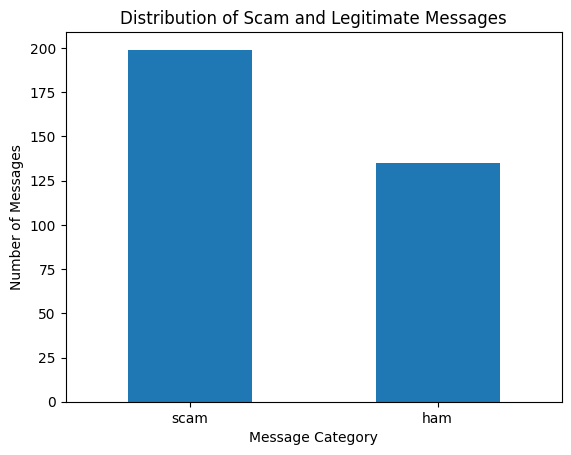

label
scam    199
ham     135
Name: count, dtype: int64

Class percentages:
label
scam    59.580838
ham     40.419162
Name: proportion, dtype: float64


In [6]:
import matplotlib.pyplot as plt

# Count messages belonging to each class
class_counts = train_df['label'].value_counts()

# Visualise class distribution
class_counts.plot(kind='bar')

plt.title('Distribution of Scam and Legitimate Messages')
plt.xlabel('Message Category')
plt.ylabel('Number of Messages')
plt.xticks(rotation=0)
plt.show()

# Display numerical results
print(class_counts)
print("\nClass percentages:")
print(train_df['label'].value_counts(normalize=True) * 100)


### 4.2 Message Length Analysis
The following investigates whether scam and legitimate messages differ in length.

#### Observation
Scam messages were generally longer than legitimate messages. This suggests that scam messages tend to contain slightly more text, although message length alone cannot determine whether a message is a scam.

--- Message Length Summary Statistics ---


char_len                 word_count               
          mean median min  max       mean median min max
label                                                   
ham       62.5   63.0  21  153       10.4   10.0   3  30
scam      73.0   70.0  33  187       11.5   11.0   5  33

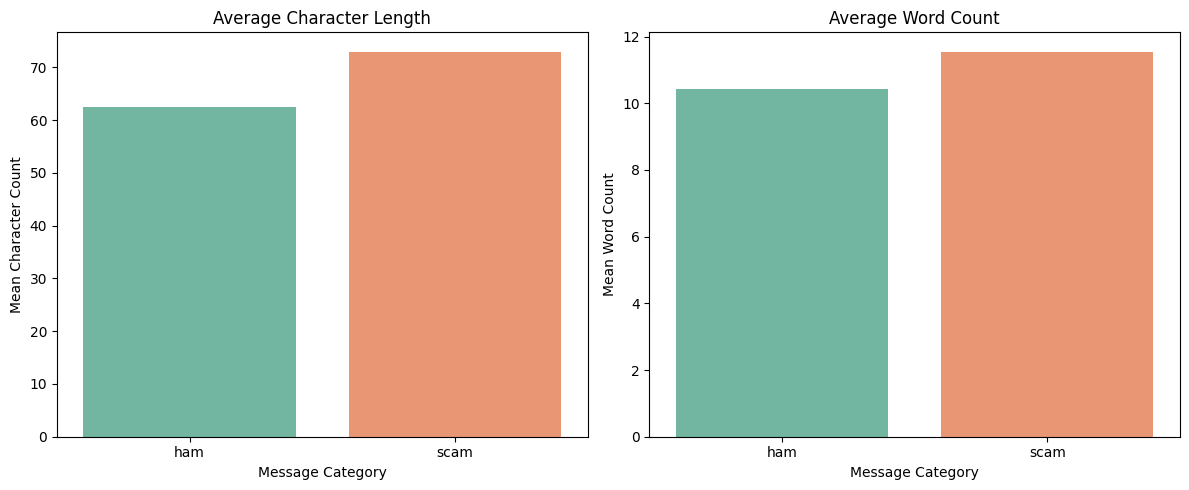

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy for EDA
eda = train_df.copy()

# Calculate message lengths
eda["char_len"] = eda["message"].str.len()
eda["word_count"] = eda["message"].str.split().str.len()

# Compare the two categories numerically
print("--- Message Length Summary Statistics ---")
display(eda.groupby("label")[["char_len", "word_count"]].agg(
    ["mean", "median", "min", "max"]
).round(1))

# Calculate means for the bar chart
mean_stats = eda.groupby("label")[["char_len", "word_count"]].mean().reset_index()

# Visualise the averages using simple bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Average Character Length
sns.barplot(ax=axes[0], x="label", y="char_len", data=mean_stats, palette="Set2", hue="label", legend=False)
axes[0].set_title("Average Character Length")
axes[0].set_xlabel("Message Category")
axes[0].set_ylabel("Mean Character Count")

# Plot 2: Average Word Count
sns.barplot(ax=axes[1], x="label", y="word_count", data=mean_stats, palette="Set2", hue="label", legend=False)
axes[1].set_title("Average Word Count")
axes[1].set_xlabel("Message Category")
axes[1].set_ylabel("Mean Word Count")

plt.tight_layout()
plt.show()

### 4.3 Suspicious text patterns
We selected characteristics commonly associated with scam messages to investigate whether they occur more frequently in scam-labelled messages.

#### Observation
Scam messages used more urgency words, credential-related words such as OTP and password and exclamation marks than legitimate messages.


In [8]:

# Define suspicious text patterns
patterns = {
    "URL": r"https?://|www\.",
    "Exclamation Mark": r"!",
    "Credential Words": r"\b(?:password|otp|pin|verify)\b",
    "Urgency Words": r"\b(?:urgent|immediately|now|expire)\b"
}

# Check whether each message contains a pattern
for name, pattern in patterns.items():
    eda[name] = eda["message"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

# Calculate percentage of messages containing each pattern
pattern_summary = (
    eda.groupby("label")[list(patterns.keys())]
    .mean() * 100
).round(1)

print("Percentage of messages containing each pattern:")
display(pattern_summary)


Percentage of messages containing each pattern:


,URL,Exclamation Mark,Credential Words,Urgency Words
label,,,,
ham,0.0,5.9,3.0,2.2
scam,0.5,30.7,30.2,44.2


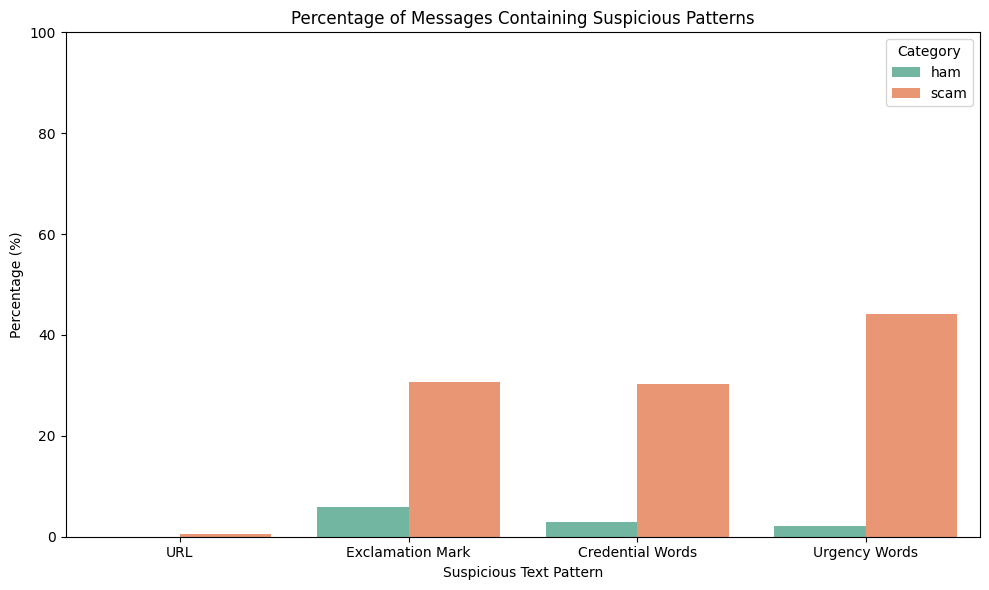

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape the pattern summary for easier plotting with seaborn
plot_data = pattern_summary.reset_index().melt(
    id_vars="label",
    var_name="Pattern",
    value_name="Percentage"
)

# Visualise the suspicious patterns using a simple bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x="Pattern", y="Percentage", hue="label", data=plot_data, palette="Set2")

plt.title("Percentage of Messages Containing Suspicious Patterns")
plt.xlabel("Suspicious Text Pattern")
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

### 4.4 Common word frequency
We examined the frequently used words in each message category to identify possible differences in language patterns.

#### Observation
scam-labelled messages frequently contain reward and verification-related words, while legitimate messages commonly contain transactional and conversational words.

TOP 10 WORDS IN SCAM MESSAGES
claim: 53
bdt: 40
verify: 33
account: 32
otp: 28
congratulations: 23
free: 22
details: 20
card: 20
bank: 19

TOP 10 WORDS IN LEGITIMATE MESSAGES
bdt: 62
payment: 24
thank: 19
successfully: 19
tomorrow: 14
check: 13
sent: 12
successful: 10
today: 10
account: 10


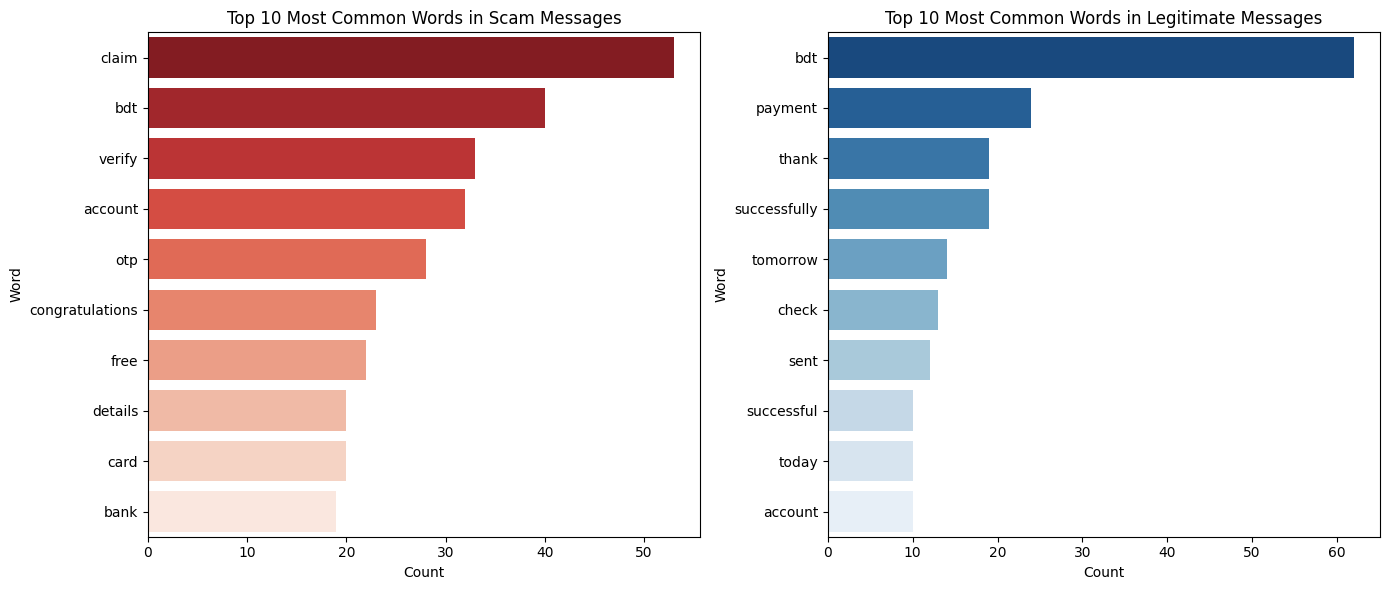

In [27]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Function to extract common words
def common_words(messages):
    words = []
    for message in messages:
        tokens = re.findall(r"\b[a-z]+\b", message.lower())
        words.extend(
            word for word in tokens
            if word not in ENGLISH_STOP_WORDS and len(word) > 2
        )
    return Counter(words).most_common(10)

# Find common words in each category
scam_words = common_words(eda[eda["label"] == "scam"]["message"])
ham_words = common_words(eda[eda["label"] == "ham"]["message"])

print("TOP 10 WORDS IN SCAM MESSAGES")
for word, count in scam_words:
    print(f"{word}: {count}")

print("\nTOP 10 WORDS IN LEGITIMATE MESSAGES")
for word, count in ham_words:
    print(f"{word}: {count}")

# Convert to DataFrames for plotting
scam_df = pd.DataFrame(scam_words, columns=["Word", "Count"])
ham_df = pd.DataFrame(ham_words, columns=["Word", "Count"])

# Plot the top words side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Scam Words
sns.barplot(ax=axes[0], x="Count", y="Word", data=scam_df, palette="Reds_r", hue="Word", legend=False)
axes[0].set_title("Top 10 Most Common Words in Scam Messages")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Word")

# Plot 2: Ham Words
sns.barplot(ax=axes[1], x="Count", y="Word", data=ham_df, palette="Blues_r", hue="Word", legend=False)
axes[1].set_title("Top 10 Most Common Words in Legitimate Messages")
axes[1].set_xlabel("Count")
axes[1].set_ylabel("Word")

plt.tight_layout()
plt.show()

## 5. Financial Scam Detection: Model Development

### 5.1 Algorithm Selection
Multinomial Naive Bayes was selected as the baseline classification algorithm because it is computationally efficient and suitable for text classification. TF-IDF converts text messages into numerical features for the model.

### 5.2 Preprocessing
The dataset contains 418 cleaned English-language messages labelled as scam or ham. The supplied stratified split contains 334 training messages and 84 testing messages. The `message` column is the input, and `label` is the target.

### 5.3 Model Training and Evaluation
The model is trained using the training dataset only. TF-IDF is fitted on training messages and then applied to the test messages. Accuracy, precision, recall, F1-score, and the confusion matrix are used to evaluate performance.

In [11]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cleaned_df = pd.read_csv("/content/financial_scams_cleaned.csv")
train_df = pd.read_csv("/content/financial_scams_train.csv")
test_df = pd.read_csv("/content/financial_scams_test.csv")

print("Cleaned dataset:", cleaned_df.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

Cleaned dataset: (418, 3)
Training dataset: (334, 3)
Testing dataset: (84, 3)

Training label distribution:
label
scam    199
ham     135
Name: count, dtype: int64


In [12]:
X_train = train_df["message"].astype(str)
y_train = train_df["label"]

X_test = test_df["message"].astype(str)
y_test = test_df["label"]

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("Training labels:", y_train.value_counts().to_dict())

Training messages: 334
Testing messages: 84
Training labels: {'scam': 199, 'ham': 135}


In [13]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of vocabulary features:", len(vectorizer.vocabulary_))

Training feature shape: (334, 2208)
Testing feature shape: (84, 2208)
Number of vocabulary features: 2208


In [14]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [15]:
y_pred = model.predict(X_test_tfidf)

predictions_df = pd.DataFrame({
    "message": X_test,
    "actual_label": y_test,
    "predicted_label": y_pred
})

display(predictions_df.head(10))

predictions_df.to_csv(
    "/content/financial_scams_predictions.csv",
    index=False
)

print("Predictions saved successfully.")

,message,actual_label,predicted_label
0,Friend request from Rafi Ahmed. Accept to conn...,ham,ham
1,"Dear user, update your payment info to avoid a...",scam,scam
2,Warning! Your account has been suspended due t...,scam,scam
3,PayPal alert: Unverified login attempt blocked...,scam,scam
4,Verify your identity to avoid account suspensi...,scam,scam
5,Earn BDT 3000 daily from home. Register now!,scam,scam
6,"I sent 1,800 BDT to settle the grocery expense...",ham,ham
7,Crypto investment deal: Deposit $100 and earn ...,scam,scam
8,Event reminder: Music concert tonight at 7 PM ...,ham,ham
9,"Claim your BDT 15,000 bonus credits from our n...",scam,scam


Predictions saved successfully.


In [16]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred, labels=["ham", "scam"]))

Accuracy: 0.881

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      0.74      0.83        34
        scam       0.84      0.98      0.91        50

    accuracy                           0.88        84
   macro avg       0.90      0.86      0.87        84
weighted avg       0.89      0.88      0.88        84


Confusion Matrix (rows = actual, columns = predicted):
[[25  9]
 [ 1 49]]


## 6. Model Validation: 5-Fold Stratified Cross-Validation

To check that the baseline results are not just due to one lucky train/test split,
we ran 5-fold stratified cross-validation on the training set only (334 messages).
The data is split into 5 folds. Each fold is used once for validation while the
other 4 train the model. Stratified means every fold keeps roughly the same
scam/ham proportion (about 60/40). The TF-IDF vectorizer is inside a Pipeline so
it is fitted on the training folds only, which prevents data leakage.
The test set was not used here.

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

X_cv = train_df["message"].astype(str)
y_cv = train_df["label_id"]          # 1 = scam, 0 = ham

# Same settings as the baseline model
pipe = make_pipeline(
    TfidfVectorizer(lowercase=True, stop_words="english",
                    ngram_range=(1, 2), max_features=5000),
    MultinomialNB()
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1"]

cv_results = cross_validate(pipe, X_cv, y_cv, cv=skf, scoring=scoring)

In [18]:
cv_table = pd.DataFrame({m: cv_results["test_" + m] for m in scoring})
cv_table.index = [f"Fold {i}" for i in range(1, 6)]
cv_table.loc["Mean"] = cv_table.iloc[:5].mean()
cv_table.loc["Std"] = cv_table.iloc[:5].std()
display(cv_table.round(3))

,accuracy,precision,recall,f1
Fold 1,0.881,0.900,0.900,0.900
Fold 2,0.910,0.870,1.000,0.930
Fold 3,0.851,0.800,1.000,0.889
Fold 4,0.910,0.886,0.975,0.929
Fold 5,0.894,0.848,1.000,0.918
Mean,0.889,0.861,0.975,0.913
Std,0.025,0.039,0.043,0.018


In [19]:
# Fit on full training set, score on the test set (label_id so metrics are for the scam class)
pipe.fit(X_cv, y_cv)
y_true = test_df["label_id"]
y_hat = pipe.predict(test_df["message"].astype(str))

test_scores = pd.Series({
    "accuracy": accuracy_score(y_true, y_hat),
    "precision": precision_score(y_true, y_hat),
    "recall": recall_score(y_true, y_hat),
    "f1": f1_score(y_true, y_hat),
})

comparison = pd.DataFrame({"CV mean": cv_table.loc["Mean"], "Test set": test_scores})
comparison["Difference"] = comparison["Test set"] - comparison["CV mean"]
display(comparison.round(3))

,CV mean,Test set,Difference
accuracy,0.889,0.881,-0.008
precision,0.861,0.845,-0.016
recall,0.975,0.980,0.005
f1,0.913,0.907,-0.006


### 6.1 CV results and comparison with the test set

The average 5-fold CV scores were: accuracy 0.889, precision 0.861, recall 0.975
and F1 0.913. The standard deviations were small (0.018 to 0.043), meaning the
model's performance was stable across folds. The lowest fold was Fold 3, with an
accuracy of 0.851 and a precision of 0.800.

On the test set the scores were: accuracy 0.881, precision 0.845, recall 0.980
and F1 0.907. These are very close to the CV averages (differences of less than
2 percentage points), so the model generalises reasonably well and is not
overfitting. Note that the test set has only 84 messages, so one wrong prediction
changes accuracy by about 1.2%, and the CV result is the more stable estimate.

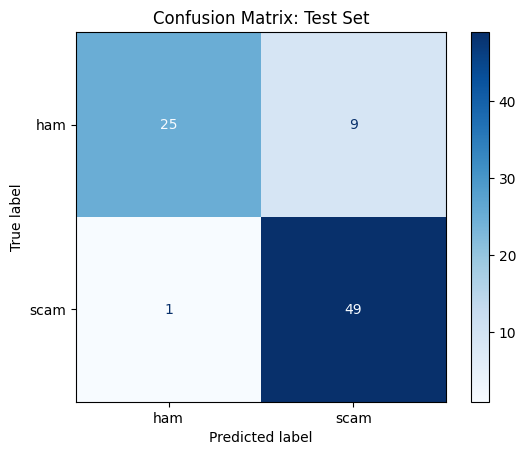

True Negatives (ham correctly kept): 25
False Positives (ham wrongly flagged as scam): 9
False Negatives (scam missed, labelled ham): 1
True Positives (scam correctly caught): 49


In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true, y_hat, display_labels=["ham", "scam"], cmap="Blues")
plt.title("Confusion Matrix: Test Set")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
print(f"True Negatives (ham correctly kept): {tn}")
print(f"False Positives (ham wrongly flagged as scam): {fp}")
print(f"False Negatives (scam missed, labelled ham): {fn}")
print(f"True Positives (scam correctly caught): {tp}")

## 7. Interpretation of Baseline Results

Out of 84 test messages, the model correctly identified 49 scams (true positives)
and 25 legitimate messages (true negatives). It made 9 false positives
(legitimate messages flagged as scams) and 1 false negative (a scam classified as
legitimate).

**Why recall matters:** a false negative means a real scam reaches the user, who
could lose money, so recall is the most important metric for this app. The
model's recall was 0.98, so it missed only 1 out of 50 scams.

**Precision:** it was 0.845, meaning that about 85% of messages flagged as scams
really were scams. The lower precision comes from the 9 false positives, which
would annoy users and could make them stop trusting the alerts.

**F1-score** (0.907) balances precision and recall in one number. Overall, the
model is better at catching scams than at avoiding false alarms, and its main
weakness is false positives: 9 of the 34 legitimate test messages (26%) were
wrongly flagged.

## 8. Error Analysis

To understand where the model fails, we inspected the messages it misclassified
on the test set, and on the training set using cross_val_predict (37 messages
misclassified across the 5 folds).

### 8.1 False positives
Examples of legitimate messages wrongly flagged as scams: "Your OTP is 789654,
keep it confidential to secure your account", "Team meeting is rescheduled to
3 PM, please confirm your availability" and "Avoid fake schemes promising
overnight wealth. Stay cautious."

These messages are legitimate, but they contain words such as "OTP", "confirm"
and "fake schemes / wealth" that are common in scam messages. The model counts
individual words and cannot understand context, so it cannot tell a real OTP
notification or a warning about scams from an actual scam.

### 8.2 False negative
The one missed scam was "Your BDT 4000 electricity bill has been paid. Thank you
for your payment." It reads like a normal payment confirmation and has no typical
scam words (such as OTP, urgent or click), so the model treated it as legitimate.

### 8.3 Summary
The main causes of errors are: (1) legitimate messages containing scam-like
words, (2) the model ignoring context, and (3) scam messages that are written
like normal messages.

In [21]:
pd.set_option("display.max_colwidth", None)

errors = test_df.copy()
errors["predicted"] = y_hat
errors = errors[errors["label_id"] != errors["predicted"]]

fp_df = errors[errors["label_id"] == 0]   # actually ham, predicted scam
fn_df = errors[errors["label_id"] == 1]   # actually scam, predicted ham

print("FALSE POSITIVES (legitimate flagged as scam):", len(fp_df))
display(fp_df[["message"]])
print("FALSE NEGATIVES (scam missed):", len(fn_df))
display(fn_df[["message"]])

FALSE POSITIVES (legitimate flagged as scam): 9


,message
11,Your software update is ready to install. Proceed now.
15,A new login to your account was detected from an unknown device. Secure your login now.
19,"Your insurance claim was approved. BDT 15,000 will be credited to your account shortly."
25,Do you want to join the study group this evening?
48,OTP verification failed. Please try again.
49,Settled the vendor payment through bank draft just now. Awaiting your acknowledgment
67,Alert: Suspicious account activity detected. Verify your info immediately.
70,You have a new message from the lottery office. Claim winnings.
77,Your mobile data has been recharged with 2GB. Enjoy surfing.


FALSE NEGATIVES (scam missed): 1


,message
45,Your BDT 4000 electricity bill has been paid. Thank you for your payment.


In [22]:
from sklearn.model_selection import cross_val_predict

cv_pred = cross_val_predict(pipe, X_cv, y_cv, cv=skf)
cv_errors = train_df.assign(predicted=cv_pred)
cv_errors = cv_errors[cv_errors["label_id"] != cv_errors["predicted"]]
print("CV misclassified:", len(cv_errors))
display(cv_errors[["message", "label", "predicted"]].head(15))

CV misclassified: 37


,message,label,predicted
1,Your subscription is about to expire. Renew now for uninterrupted service.,scam,0
3,Can you share the bank details for transferring the rent money?,ham,1
20,Your subscription will expire tomorrow. Renew to continue service.,ham,1
24,Avoid fake schemes promising overnight wealth. Stay cautious.,ham,1
27,"Your OTP is 789654, keep it confidential to secure your account.",ham,1
29,Your credit card limit has been increased. Check details in app.,ham,1
32,Your package delivery is delayed. Track now at this fake link.,scam,0
39,Your health insurance claim has been approved. Contact for details.,ham,1
46,"Your bank transfer of BDT 10,000 has been successfully processed",ham,1
64,"Team meeting is rescheduled to 3 PM, please confirm your availability.",ham,1


## 9. Model Limitations

1. **Small dataset:** only 334 training and 84 test messages, so scores change a lot
   with a few messages and the model may memorise phrases.
2. **Class imbalance:** 59.6% scam vs 40.4% ham. It is mild, but the model can
   favour the majority class, so we used recall and F1 and not just accuracy.
3. **Bangladesh-specific vocabulary:** the data contains BDT, bKash, Nagad and
   +880 numbers, so the model may not work on Kenyan messages (Ksh, M-Pesa,
   Swahili/Sheng).
4. **English only:** Bengali-script messages were removed, so the model cannot
   handle them.
5. **Limited context:** messages are short (about 11 words on average) and Naive
   Bayes treats words independently, so it misses context. Our error analysis showed that legitimate messages containing words like "OTP" or "confirm" were wrongly flagged.

## 10. Recommendations for Future Improvement

- Collect more data, especially Kenyan SMS/M-Pesa scams, and balance the classes.
- Normalise currency and phone details (e.g. replace amounts and numbers with tags).
- Compare other algorithms: Logistic Regression, Linear SVM, Random Forest.
- Tune the decision threshold or use class weights to push recall higher.
- Try character n-grams and, later, multilingual or transformer models.
- Use repeated stratified CV for more stable estimates.